# 17 分単位の座席利用・待ち行列

2022〜2024年の全来店ログから、各店舗で**使用中の卓の定員合計**・着席客数・待ち組数を分単位で再構成する。集計は到着・着席を含み、退店・離脱の時刻を含まない半開区間 `[start, end)` とする。卓定員の占有率は、その日のレイアウトの総席数を分母にする。

これはログ上の卓・客の占有であり、店舗の全施設利用や売上の因果分析ではない。来店・退店は同時点で得られる実績なので、2025年の同日時刻の予測特徴量には使えない。

In [1]:
from pathlib import Path
import zipfile,io
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'input').is_dir(): ROOT=ROOT.parent
assert (ROOT/'input').is_dir()
INPUT=ROOT/'input';sns.set_theme(style='whitegrid');pd.options.display.float_format='{:,.4f}'.format
stores=pd.read_csv(INPUT/'stores.csv')
layout=pd.read_csv(INPUT/'seat_layout.csv',parse_dates=['effective_start_date','effective_end_date'])
dates=pd.date_range('2022-01-01','2024-12-31');origin=dates[0];total_minutes=len(dates)*1440;extra_minutes=1440
assert len(dates)==1096
print('対象:',dates.min().date(),'〜',dates.max().date(),'店舗数:',len(stores))

対象: 2022-01-01 〜 2024-12-31 店舗数: 10


## ログを分単位に復元
占有卓の定員と着席客数は着席〜退店、待ち組数は到着〜着席または離脱。営業時間は `stores.csv` の開始を含み終了を含まない。同一卓の重複は `16_visit_integrity.ipynb` で検査済み。

In [2]:
hourly_parts=[];daily_parts=[];quality=[]
def minute_offsets(times):
    return ((times-origin)/pd.Timedelta(minutes=1)).to_numpy(dtype=np.int64)
def interval_counts(starts,ends,weights):
    start=minute_offsets(starts);end=minute_offsets(ends);weights=np.asarray(weights,dtype=np.int64)
    assert len(start)==len(end)==len(weights)
    assert (start>=0).all() and (end>=start).all() and (end<=total_minutes+extra_minutes).all()
    diff=np.zeros(total_minutes+extra_minutes+1,dtype=np.int64)
    np.add.at(diff,start,weights);np.add.at(diff,end,-weights)
    count=np.cumsum(diff)[:total_minutes]
    assert (count>=0).all()
    return count.reshape(len(dates),1440)

def get_minutes(value):
    h,m=map(int,value.split(':'));return h*60+m
with zipfile.ZipFile(INPUT/'logs.zip') as z:
    for store in stores.itertuples(index=False):
        sid=store.store_id
        with z.open(f'logs/{sid}/visit_log.parquet') as f:
            v=pq.read_table(io.BytesIO(f.read()),columns=['date','arrival_time','seat_time','departure_time','left_time','group_size','table_capacity','is_seated','is_left']).to_pandas()
        seated=v[v.is_seated].copy()
        # 元の時刻が分精度であることを検査し、下方向の丸めで件数が変わらないようにする。
        for col in ['arrival_time','seat_time','departure_time','left_time']:
            valid=v[col].dropna();assert ((valid.dt.second==0)&(valid.dt.microsecond==0)&(valid.dt.nanosecond==0)).all(),(sid,col)
        held=interval_counts(seated.seat_time,seated.departure_time,seated.table_capacity)
        guests=interval_counts(seated.seat_time,seated.departure_time,seated.group_size)
        waiting_end=v.seat_time.where(v.is_seated,v.left_time)
        waiting=interval_counts(v.arrival_time,waiting_end,np.ones(len(v),dtype=np.int64))
        assert (guests<=held).all()
        history=layout[layout.store_id.eq(sid)].copy()
        history['date']=[pd.date_range(a,b) for a,b in zip(history.effective_start_date,history.effective_end_date)]
        history=history.explode('date',ignore_index=True)[['date','total_seats']]
        history=history[history.date.between(dates.min(),dates.max())]
        assert not history.date.duplicated().any()
        seats=pd.DataFrame({'date':dates}).merge(history,on='date',how='left',validate='one_to_one')
        assert seats.total_seats.notna().all() and seats.total_seats.gt(0).all()
        seats_array=seats.total_seats.to_numpy(dtype=float)
        start,end=get_minutes(store.business_start_time),get_minutes(store.business_end_time)
        assert end>start and start%60==0 and end%60==0
        hrs=(end-start)//60
        held_open=held[:,start:end].reshape(len(dates),hrs,60)
        guest_open=guests[:,start:end].reshape(len(dates),hrs,60)
        wait_open=waiting[:,start:end].reshape(len(dates),hrs,60)
        denom=seats_array[:,None,None]
        occupied=held_open/denom;guest_fraction=guest_open/denom
        quality.append({'store_id':sid,'visits':len(v),'seated':len(seated),'minutes_checked':occupied.size,'minutes_over_capacity':int((occupied>1+1e-9).sum()),'max_occupied_fraction':float(occupied.max()),'seated_cross_date':int((seated.seat_time.dt.normalize()!=seated.departure_time.dt.normalize()).sum())})
        frame=pd.DataFrame({'date':np.repeat(dates.to_numpy(),hrs),'hour':np.tile(np.arange(start//60,end//60),len(dates)),
          'occupied_fraction':occupied.mean(axis=2).ravel(),'guest_fraction':guest_fraction.mean(axis=2).ravel(),
          'waiting_groups':wait_open.mean(axis=2).ravel(),'near_full_fraction':(occupied>=.9).mean(axis=2).ravel()})
        frame['store_id']=sid;hourly_parts.append(frame)
        visit_daily=v.groupby('date',observed=True).agg(groups=('date','size'),left=('is_left','sum')).reset_index()
        day=frame.groupby('date',observed=True).agg(occupied_fraction=('occupied_fraction','mean'),guest_fraction=('guest_fraction','mean'),waiting_groups=('waiting_groups','mean'),near_full_fraction=('near_full_fraction','mean')).reset_index().merge(visit_daily,on='date',validate='one_to_one')
        day['store_id']=sid;daily_parts.append(day)
        print(sid,'来店行:',len(v),'営業時間の定員超過分:',quality[-1]['minutes_over_capacity'],flush=True)
        del v,seated,held,guests,waiting,held_open,guest_open,wait_open,occupied,guest_fraction
quality=pd.DataFrame(quality);hourly=pd.concat(hourly_parts,ignore_index=True);daily=pd.concat(daily_parts,ignore_index=True)
print('全来店行:',quality.visits.sum(),'営業時間の定員超過分:',quality.minutes_over_capacity.sum())
display(quality)
assert quality.visits.sum()==2491880 and len(daily)==10960

S001 来店行: 335479 営業時間の定員超過分: 0
S002 来店行: 308798 営業時間の定員超過分: 0
S003 来店行: 255933 営業時間の定員超過分: 0
S004 来店行: 285398 営業時間の定員超過分: 0
S005 来店行: 214109 営業時間の定員超過分: 0
S006 来店行: 162109 営業時間の定員超過分: 0
S007 来店行: 193307 営業時間の定員超過分: 0
S008 来店行: 227188 営業時間の定員超過分: 0
S009 来店行: 151785 営業時間の定員超過分: 0
S010 来店行: 357774 営業時間の定員超過分: 0
全来店行: 2491880 営業時間の定員超過分: 0


,store_id,visits,seated,minutes_checked,minutes_over_capacity,max_occupied_fraction,seated_cross_date
0,S001,335479,302739,854880,0,1.0000,0
1,S002,308798,293032,854880,0,1.0000,0
2,S003,255933,228881,854880,0,1.0000,0
3,S004,285398,249291,854880,0,1.0000,0
4,S005,214109,204652,854880,0,1.0000,0
5,S006,162109,161552,854880,0,1.0000,0
6,S007,193307,190114,854880,0,1.0000,0
7,S008,227188,225940,854880,0,1.0000,0
8,S009,151785,150621,854880,0,1.0000,0
9,S010,357774,330660,854880,0,1.0000,0


## 店舗・時間帯ごとの利用状況
占有率は卓の定員に対する予約済み席の割合、着席客率は着席人数の割合。営業時間の分単位値を日・時間帯で平均する。

,occupied_fraction,guest_fraction,waiting_groups,near_full_fraction
store_id,,,,
S001,0.6556,0.4733,1.4501,0.3872
S002,0.5596,0.4179,0.7840,0.2804
S003,0.6524,0.5507,1.1288,0.2194
S004,0.7865,0.5950,1.5833,0.5202
S005,0.5193,0.4440,0.3824,0.0417
S006,0.3615,0.3218,0.0281,0.0115
S007,0.4863,0.4055,0.1557,0.0607
S008,0.3753,0.3176,0.0662,0.0433
S009,0.3465,0.3074,0.0487,0.0111


,area_type,hour,occupied_fraction,guest_fraction,waiting_groups,near_full_fraction
0,office,10,0.1178,0.1080,0.0003,0.0000
1,office,11,0.5084,0.3926,0.4437,0.1741
2,office,12,0.7783,0.5471,1.7014,0.5116
3,office,13,0.7549,0.5320,0.9107,0.4019
4,office,14,0.4393,0.3461,0.0257,0.0256
...,...,...,...,...,...,...
60,urban_core,18,0.9663,0.7269,4.7667,0.9456
61,urban_core,19,0.9564,0.7087,3.4679,0.8972
62,urban_core,20,0.7675,0.5831,0.5992,0.2776
63,urban_core,21,0.3575,0.2913,0.0145,0.0057


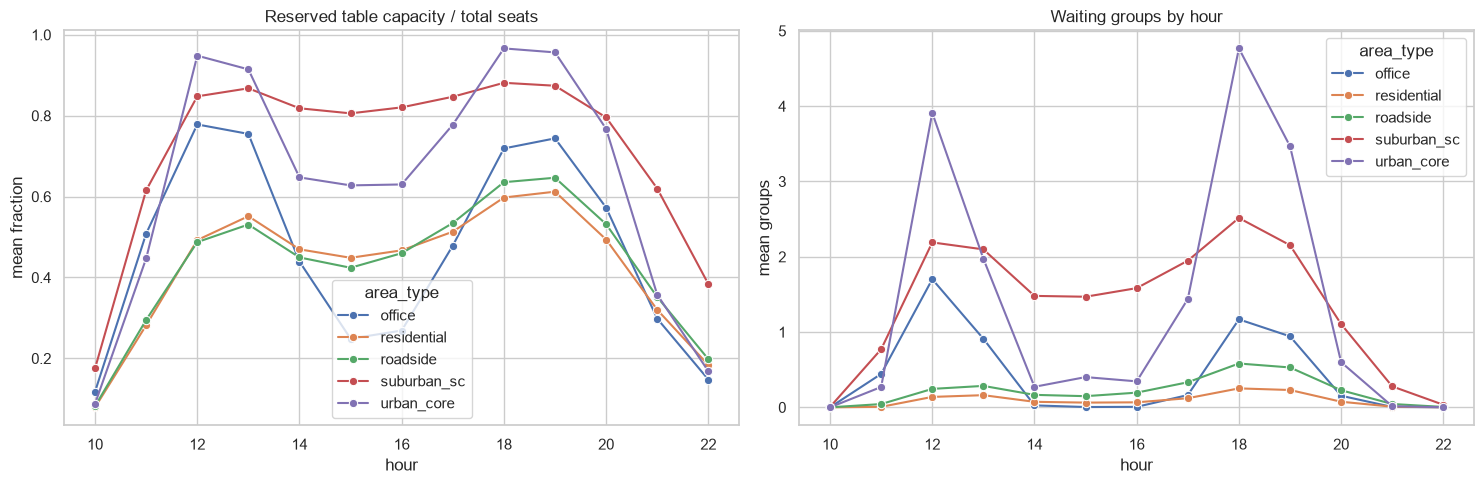

In [3]:
hourly=hourly.merge(stores[['store_id','area_type']],on='store_id',validate='many_to_one')
daily=daily.merge(stores[['store_id','area_type']],on='store_id',validate='many_to_one')
daily['left_rate']=daily.left/daily.groups
by_store=hourly.groupby('store_id',observed=True).agg(occupied_fraction=('occupied_fraction','mean'),guest_fraction=('guest_fraction','mean'),waiting_groups=('waiting_groups','mean'),near_full_fraction=('near_full_fraction','mean'))
display(by_store)
area_hour=hourly.groupby(['area_type','hour'],observed=True).agg(occupied_fraction=('occupied_fraction','mean'),guest_fraction=('guest_fraction','mean'),waiting_groups=('waiting_groups','mean'),near_full_fraction=('near_full_fraction','mean')).reset_index()
display(area_hour)
fig,ax=plt.subplots(1,2,figsize=(15,5));sns.lineplot(data=area_hour,x='hour',y='occupied_fraction',hue='area_type',marker='o',ax=ax[0]);ax[0].set(title='Reserved table capacity / total seats',ylabel='mean fraction');sns.lineplot(data=area_hour,x='hour',y='waiting_groups',hue='area_type',marker='o',ax=ax[1]);ax[1].set(title='Waiting groups by hour',ylabel='mean groups');plt.tight_layout();plt.show()

## 曜日・時間帯と混雑
店舗・曜日・時間の平均で、全席数の90%以上が利用中だった分の割合を表示。90%は探索用の閾値であり、満席・入店不能を意味しない。卓構成や人数により、残席があっても空いている卓の定員が合わない場合がある。

,near_full_fraction,waiting_groups
store_id,,
S001,0.3872,1.4498
S002,0.2806,0.7845
S003,0.2193,1.1277
S004,0.5200,1.5821
S005,0.0417,0.3819
S006,0.0115,0.0281
S007,0.0607,0.1555
S008,0.0434,0.0662
S009,0.0111,0.0486


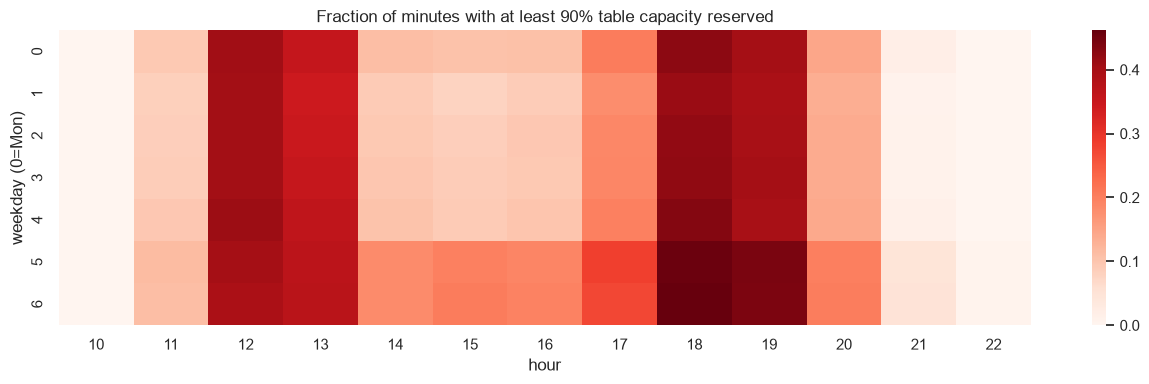

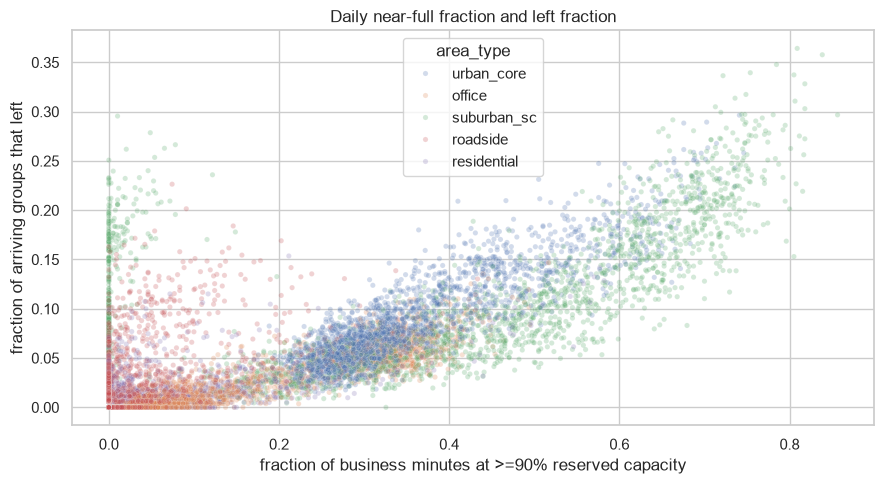

In [4]:
hourly['weekday']=hourly.date.dt.dayofweek
week=hourly.groupby(['store_id','weekday','hour'],observed=True).agg(near_full_fraction=('near_full_fraction','mean'),waiting_groups=('waiting_groups','mean')).reset_index()
display(week.groupby('store_id')[['near_full_fraction','waiting_groups']].mean())
weekday_hour=hourly.groupby(['weekday','hour'],observed=True).near_full_fraction.mean().unstack()
fig,ax=plt.subplots(figsize=(13,4));sns.heatmap(weekday_hour.astype(float),cmap='Reds',ax=ax);ax.set(title='Fraction of minutes with at least 90% table capacity reserved',ylabel='weekday (0=Mon)');plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(9,5));sns.scatterplot(data=daily,x='near_full_fraction',y='left_rate',hue='area_type',alpha=.25,s=14,ax=ax);ax.set(title='Daily near-full fraction and left fraction',xlabel='fraction of business minutes at >=90% reserved capacity',ylabel='fraction of arriving groups that left');plt.tight_layout();plt.show()

## 解釈上の注意
- 予約済み卓の定員は実際に着席している人数とは異なる。定員の未使用部分は `16_visit_integrity.ipynb` を参照。
- 90%以上は分析上の目安で、空席・卓の適合や入店可否を直接表さない。
- 占有、待ち、離脱は同じ日の実績であり、2025年の同日特徴量には使えない。また、相関は原因・結果の証明にならない。
- 営業時間外の占有は品質検査の最大値に含めず、日をまたぐ区間は連続時間上で保持してから各日の営業時間を集計する。